# The kicked rotor

A rotor, a particle on a ring with angle $\theta$, is kicked periodically by a force that depends on
its position:

$$H = \frac{p^2}{2} + k\cos\theta\,\sum_n \delta(t - n\tau).$$

Classically, the angle and momentum just after each kick follow the *standard map*. For a
stochasticity parameter $K = k\tau \gtrsim 1$ the motion is chaotic, and the momentum performs a
random walk: the kinetic energy grows linearly with the number of kicks.

The quantum rotor follows the classical diffusion only for a while. Then interference stops it:
the momentum distribution freezes into an exponential, $|\psi(p)|^2 \sim e^{-2|p|/\xi}$. This *dynamical
localization* (Casati, Chirikov, Izrailev and Ford, Lect. Notes Phys. **93**, 334 (1979)) is Anderson
localization in momentum space (Fishman, Grempel and Prange, Phys. Rev. Lett. **49**, 509 (1982), and
notebook 07), and was observed with cold atoms in a pulsed standing wave of light (Moore et al.,
Phys. Rev. Lett. **75**, 4598 (1995)).

In [1]:
# On Colab or JupyterLite (or anywhere without the package), install it first:
try:
    import so_schroedinger  # noqa: F401
except ImportError:
    import sys

    if sys.platform == "emscripten":  # JupyterLite: the package comes with the site
        %pip install so_schroedinger
    else:
        %pip install -q git+https://github.com/aeberspaecher/splitoperator

In [2]:
import matplotlib.pyplot as plt
import numpy as np

import so_schroedinger as so

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["figure.dpi"] = 72

## The kicked rotor is a split operator step

The angle lives on $[0, 2\pi)$, which is exactly a periodic grid, and with $\hbar = 1$ the momenta on it
are the integers. Between two kicks, the rotor evolves freely, $e^{-ip^2\tau/2}$; a kick multiplies $\psi$
by $e^{-ik\cos\theta}$. One period, from the middle of one kick to the middle of the next,

$$U = e^{-ik\cos\theta/2}\, e^{-ip^2\tau/2}\, e^{-ik\cos\theta/2},$$

is a single Strang step of length $\tau$ for the constant potential $V = (k/\tau)\cos\theta$. The splitting
"error" of a large time step is here the physics, so `SplitOperator().propagate(grid, tau, n)` gives
the kicked rotor exactly. The potential class below also allows for noise in the kick strengths,
used at the end; noisy kicks make the potential time dependent.

In [3]:
class Kicks(so.Potential1d):
    """Kicks k cos(theta) every tau, as a potential (k/tau) cos(theta) for steps of length tau.

    With noise > 0, kick n has the strength k (1 + noise * r_n) with normal random numbers r_n.
    """

    def __init__(self, k, tau, noise=0.0, n_max=10_000, rng=None):
        self.k, self.tau = k, tau
        self.strength = 1 + noise * np.random.default_rng(rng).standard_normal(n_max + 1)
        self.is_time_dependent = noise != 0.0

    def V(self, theta, t):
        n = int(round(t / self.tau))  # the kick at time t
        return self.k / self.tau * self.strength[n] * np.cos(theta) + 0.0j


N = 4096  # momenta -2048 ... 2047
K = 5.0  # stochasticity parameter k tau


def rotor(tau, noise=0.0, rng=None, n_max=10_000):
    """A grid with the rotor at rest, psi = 1/sqrt(2 pi)."""
    grid = so.Grid1d((0.0, 2 * np.pi), N, Kicks(K / tau, tau, noise, n_max, rng), so.Gaussian1d(np.pi, 1.0, 0.0))
    grid.psi = np.full(N, 1 / np.sqrt(2 * np.pi))
    return grid


# check against kicks applied by hand
tau = 0.5
k = K / tau
grid = rotor(tau)
so.SplitOperator().propagate(grid, tau, 50)

theta, p = grid.x_vals, grid.k_vals
psi = np.full(N, 1 / np.sqrt(2 * np.pi), dtype=complex)
half_kick, free = np.exp(-0.5j * k * np.cos(theta)), np.exp(-0.5j * p**2 * tau)
for _ in range(50):
    psi = half_kick * np.fft.ifft(free * np.fft.fft(half_kick * psi))
print(f"largest difference after 50 kicks: {np.max(np.abs(psi - grid.psi)):.1e}")

largest difference after 50 kicks: 3.8e-15


## Classical chaos

Classically, the same splitting is the leapfrog (velocity Verlet) step: half a kick
$p \to p + \tfrac{k}{2}\sin\theta$, a free flight $\theta \to \theta + \tau p$, and another half kick. In the
scaled momentum $\tau p$ the map depends on $K$ only, and is periodic in $\tau p$ with period $2\pi$. For
small $K$ most orbits are regular; above $K \approx 1$ the last curves that block the momentum growth are
destroyed, and at $K = 5$ almost all of phase space is chaotic.

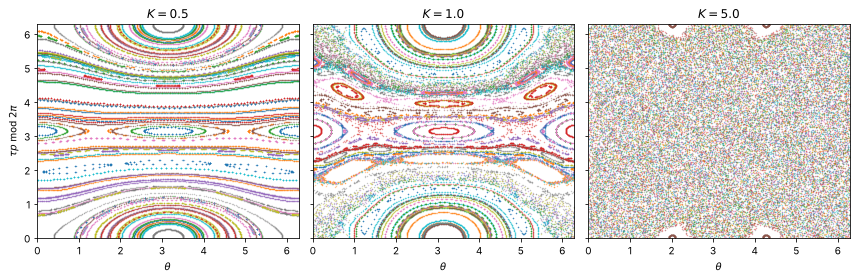

In [4]:
def standard_map(theta, p, k, tau, n_kicks):
    """Iterate the (symmetrized) kicked rotor; yields theta, p after each period."""
    for _ in range(n_kicks):
        p = p + 0.5 * k * np.sin(theta)
        theta = theta + tau * p
        p = p + 0.5 * k * np.sin(theta)
        yield theta, p


fig, axs = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
rng = np.random.default_rng(0)
for ax, K_plot in zip(axs, [0.5, 1.0, 5.0]):
    theta0, p0 = rng.uniform(0, 2 * np.pi, 80), rng.uniform(0, 2 * np.pi, 80)  # p0 is tau p, so tau = 1 here
    thetas, ps = np.array(list(standard_map(theta0, p0, K_plot, 1.0, 500))).transpose(1, 0, 2)
    ax.plot(thetas % (2 * np.pi), ps % (2 * np.pi), ".", ms=0.8, alpha=0.5)
    ax.set(title=f"$K = {K_plot}$", xlabel=r"$\theta$", xlim=(0, 2 * np.pi), ylim=(0, 2 * np.pi))
axs[0].set_ylabel(r"$\tau p$ mod $2\pi$")
plt.tight_layout()

## Diffusion and localization

We start the rotor at rest, $\psi = 1/\sqrt{2\pi}$, and follow $\langle p^2\rangle = 2\langle T\rangle$ over 2000 kicks,
together with a classical ensemble with uniformly distributed angles and $p = 0$. A single quantum
run fluctuates strongly, so we average over 20 kick periods $\tau$ between 0.45 and 0.55 at fixed
$K = 5$. Each run takes a fraction of a second.

classical diffusion constant D = 37.1 (random phase estimate k^2/2 = 50.0)


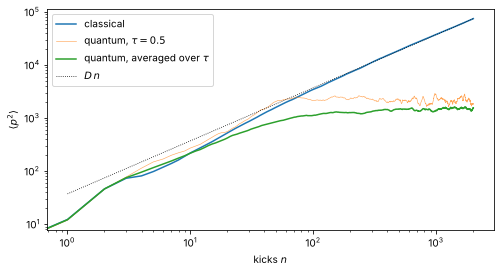

In [5]:
n_kicks = 2000
n = np.arange(n_kicks + 1)
taus = np.linspace(0.45, 0.55, 20)


def quantum(tau, noise=0.0, rng=None):
    """<p^2> after each kick and the momentum distribution averaged over the second half."""
    grid = rotor(tau, noise, rng, n_kicks)
    p2, rho = [0.0], np.zeros(N)

    def record(g):
        nonlocal rho
        p2.append(2 * g.expectation_kinetic())
        if len(p2) > n_kicks // 2:
            rho = rho + np.abs(np.fft.fft(g.psi)) ** 2

    so.SplitOperator().propagate(grid, tau, n_kicks, callback=record)
    return np.array(p2), rho / rho.sum()


runs = [quantum(tau) for tau in taus]
p2_quantum = np.mean([r[0] for r in runs], axis=0)
rho_quantum = np.fft.fftshift(np.mean([r[1] for r in runs], axis=0))
p_sorted = np.fft.fftshift(grid.k_vals)

tau = 0.5
k = K / tau
rng = np.random.default_rng(1)
classical = np.array([p for _, p in standard_map(rng.uniform(0, 2 * np.pi, 20_000), np.zeros(20_000), k, tau, n_kicks)])
p2_classical = np.concatenate([[0.0], np.mean(classical**2, axis=1)])
D = np.polyfit(n[100:], p2_classical[100:], 1)[0]  # diffusion constant per kick

plt.loglog(n, p2_classical, label="classical")
plt.loglog(n, runs[10][0], lw=0.6, alpha=0.7, label=r"quantum, $\tau = 0.5$")
plt.loglog(n, p2_quantum, label=r"quantum, averaged over $\tau$")
plt.loglog(n[1:], D * n[1:], "k:", lw=0.8, label=r"$D\,n$")
plt.xlabel("kicks $n$")
plt.ylabel(r"$\langle p^2\rangle$")
plt.legend()
print(f"classical diffusion constant D = {D:.1f} (random phase estimate k^2/2 = {k**2 / 2:.1f})")

Both follow the classical diffusion for the first few kicks; after some tens of kicks the quantum
$\langle p^2\rangle$ stops growing. The random phase estimate $k^2/2$ assumes uncorrelated kicks; the measured
$D$ is somewhat smaller because successive kicks are correlated (Rechester and White, Phys. Rev. Lett.
**44**, 1586 (1980)).

A simple argument by Chirikov, Izrailev and Shepelyansky gives the scale: after $n$ kicks, about
$\sqrt{Dn}$ momentum states are populated. The quantum evolution over one period has a discrete
spectrum (quasienergies in $[0, 2\pi)$), and the state "notices" this discreteness once $n$ exceeds the
number of quasienergies involved, $n \sim \sqrt{Dn}$. Diffusion therefore stops after $n^* \sim D$ kicks,
at a localization length $\xi \sim \sqrt{D n^*} \sim D$.

## The localized distribution

The time-averaged momentum distribution of the quantum rotor is exponential, while the classical one
is a Gaussian that keeps widening.

localization length xi = 66, classical diffusion constant D = 37


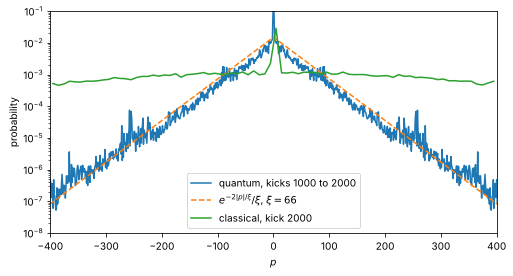

In [6]:
tail = (np.abs(p_sorted) > 20) & (np.abs(p_sorted) < 200)
slope = np.polyfit(np.abs(p_sorted[tail]), np.log(rho_quantum[tail]), 1)[0]
xi = -2 / slope

plt.semilogy(p_sorted, rho_quantum, label="quantum, kicks 1000 to 2000")
plt.semilogy(p_sorted, np.exp(-2 * np.abs(p_sorted) / xi) / xi, "--", label=rf"$e^{{-2|p|/\xi}}/\xi$, $\xi = {xi:.0f}$")
bins = np.arange(-400.5, 401, 10)
hist, _ = np.histogram(classical[-1], bins=bins, density=True)
plt.semilogy((bins[1:] + bins[:-1]) / 2, hist, label=f"classical, kick {n_kicks}")
plt.xlim(-400, 400)
plt.ylim(1e-8, 1e-1)
plt.xlabel("$p$")
plt.ylabel("probability")
plt.legend()
print(f"localization length xi = {xi:.0f}, classical diffusion constant D = {D:.0f}")

The fitted localization length is of the order of the diffusion constant, as the argument above
predicts.

## Noise destroys localization

Localization rests on the phases of $\psi$ adding up coherently from kick to kick. A little noise in the
kick strengths scrambles them, and the diffusion comes back, the faster the stronger the noise
(Ott, Antonsen and Hanson, Phys. Rev. Lett. **53**, 2187 (1984)); in the atom optics experiments,
spontaneous emission plays this role. With noise, the potential depends on the kick and is
re-evaluated every step.

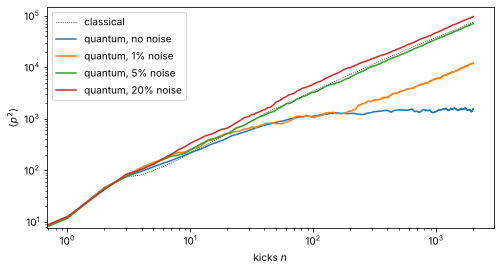

In [7]:
plt.loglog(n, p2_classical, "k:", lw=0.8, label="classical")
plt.loglog(n, p2_quantum, label="quantum, no noise")
for noise in [0.01, 0.05, 0.2]:
    p2_noisy = np.mean([quantum(0.5, noise, rng=seed)[0] for seed in range(5)], axis=0)
    plt.loglog(n, p2_noisy, label=f"quantum, {noise:.0%} noise")
plt.xlabel("kicks $n$")
plt.ylabel(r"$\langle p^2\rangle$")
plt.legend();

Things to try:

* Change $K$: below $K \approx 1$ even the classical rotor stops diffusing, because invariant curves
  block the momentum.
* *Quantum resonance*: at $\tau = 4\pi$ the free evolution $e^{-ip^2\tau/2}$ is the identity for integer $p$,
  every kick adds coherently, and $\langle p^2\rangle$ grows quadratically instead of linearly
  (Izrailev and Shepelyansky, Theor. Math. Phys. **43**, 553 (1980)).
* Watch the localized state with `so.plotting.plot_momentum(grid)`.